   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare  Survived.1  
0      0         A/5 21171   7.2500         0.0  
1      0          PC 17599  71.2833         1.0  
2      0  STON/O2. 3101282   7.9250         0.0  
3      0            113803  53.1000         0.0  
4      0            373450   8.0500         1.0  

Accuracy: 0.8324022

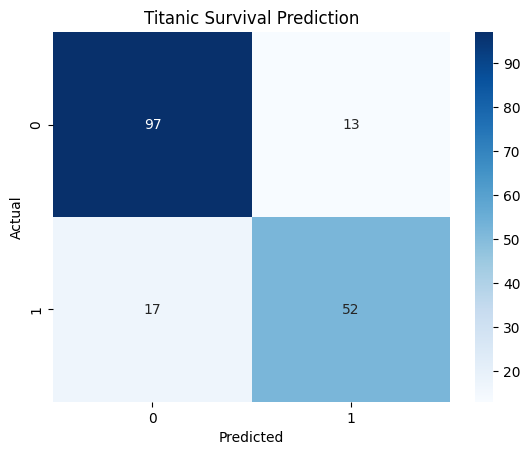

In [3]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

# 1. Load Titanic dataset
df = pd.read_csv("titanic.csv")

print(df.head())

# 2. Select relevant features
X = df[["Pclass", "Sex", "Age", "Fare"]]
y = df["Survived"]

# 3. Handle missing values
X = X.copy()

X["Age"] = X["Age"].fillna(X["Age"].median())
X["Fare"] = X["Fare"].fillna(X["Fare"].median())

# Encode categorical variable
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})

# 4. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Train Random Forest
model = RandomForestClassifier(
    n_estimators=100, random_state=42
)

model.fit(X_train, y_train)

# Predict survival
y_pred = model.predict(X_test)

# 6. Evaluate model
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Titanic Survival Prediction")
plt.show()
